## Calculating the band structure of $Al$ and $Cu$

Run all cells to calculate the band structures of $Al$ and $Cu$ using quantum-espresso based on the tutorials at https://pranabdas.github.io/espresso/

1. Load in modules
2. Plotting updates function
3. Aluminum
    1. VC Relax Calculation
    2. SCF Calculation
    3. NSCF Calculation
    4. Band Structure Calculation and Plotting
4. Copper
    1. VC Relax Calculation
    2. SCF Calculation
    3. NSCF Calculation
    4. Band Structure Calculation and Plotting

## 1. Load in modules

In [34]:
# Modules + QE setup for the Al and Cu band-structure workflow:
#   write pw.x inputs -> vc-relax -> scf -> nscf -> bands -> bands.x -> plot E(k)
import math, os, re, shutil, subprocess, time, urllib.request   # run QE executables, fetch pseudopotentials
from pathlib import Path
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = Path.cwd()
QE_BIN = ROOT / "qe" / "bin"                     # native Windows build (see build_qe.sh)
PSEUDO_DIR = ROOT / "pseudo"
RUNS = ROOT / "runs"
AL_RUN = RUNS / "bg_al_live"
CU_RUN = RUNS / "bg_cu_live"
AL_RUN.mkdir(parents=True, exist_ok=True)
CU_RUN.mkdir(parents=True, exist_ok=True)
PSEUDO_DIR.mkdir(exist_ok=True)

os.environ["PATH"] = str(QE_BIN) + os.pathsep + os.environ["PATH"]   # bundled MinGW DLLs live here too
# One thread is far faster for small cells on this build (Si SCF: 2.5 s on 1 thread, about 190 s on 12)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ.setdefault("OMP_STACKSIZE", "256M")   # OpenMP threads overflow the default Windows stack
os.environ.setdefault("ESPRESSO_PSEUDO", str(PSEUDO_DIR))

PW = shutil.which("pw.x.exe", path=str(QE_BIN))
BANDS = shutil.which("bands.x.exe", path=str(QE_BIN))
assert PW and BANDS, f"pw.x / bands.x not found in {QE_BIN}"

AL_PSEUDO = "Al.pbe-n-rrkjus_psl.1.0.0.UPF"
CU_PSEUDO = "Cu.pbe-dn-rrkjus_psl.1.0.0.UPF"
for pseudo in (AL_PSEUDO, CU_PSEUDO):
    if not (PSEUDO_DIR / pseudo).exists():
        urllib.request.urlretrieve(f"https://pseudopotentials.quantum-espresso.org/upf_files/{pseudo}", PSEUDO_DIR / pseudo)

def run_qe(exe, inp: Path, out: Path | None = None):
    """Run a QE executable on `inp` inside its folder, write stdout to `out` (default: .in -> .out)."""
    inp = Path(inp)
    out = Path(out) if out else inp.with_suffix(".out")
    with open(inp) as fin, open(out, "w") as fout:
        res = subprocess.run([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
    if res.returncode != 0 or "JOB DONE" not in out.read_text(errors="ignore"):
        raise RuntimeError(f"{Path(exe).name} failed on {inp.name} - see {out}")
    return out

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f" - {detail}" if detail else ""))

print("pw.x   :", PW)
print("bands.x:", BANDS)
for pseudo in (AL_PSEUDO, CU_PSEUDO):
    check("Pseudopotential available", "PP_HEADER" in (PSEUDO_DIR / pseudo).read_text(errors="ignore"), pseudo)

pw.x   : C:\Users\Caesium\Desktop\qe_exp\qe\bin\pw.x.exe
bands.x: C:\Users\Caesium\Desktop\qe_exp\qe\bin\bands.x.exe
[PASS] Pseudopotential available - Al.pbe-n-rrkjus_psl.1.0.0.UPF
[PASS] Pseudopotential available - Cu.pbe-dn-rrkjus_psl.1.0.0.UPF


## 2. Plotting updates function

`run_pw` writes an input file, runs `pw.x`, and redraws a plot every second so you can see how close the calculation is to finishing. It then checks the result and stops the notebook if the run failed. Stopping the cell also stops `pw.x`.

- **VC relax:** each error against its target. Errors that are exactly 0, like the force on a single atom in an fcc cell, aren't plotted.
- **SCF:** accuracy per iteration against `conv_thr`.
- **NSCF and bands:** k-points finished out of the total. These need `verbosity = 'high'`, otherwise `pw.x` doesn't report them.

In [35]:
# Live monitor: pw.x writes to its .out file as it runs, so we re-read that file every
# second and redraw one figure in place. Each calculation type gets its own view:
#   vc-relax    -> relaxation errors against their targets, and pressure, per cycle
#   scf         -> accuracy against conv_thr, per iteration
#   nscf, bands -> k-points finished, out of the total (needs verbosity = 'high')
# Time left is an estimate. A relaxation gets none: its number of cycles can't be predicted.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, TRACK, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#f0efec", "#fcfcfb"
RELAX_SERIES = (("energy_err", "Energy", BLUE, "o"), ("grad_err", "Force", ORANGE, "s"), ("cell_err", "Pressure", AQUA, "^"))

def read_setting(settings, name, default):
    """Read a number from a pw.x input. \b stops conv_thr also matching etot_conv_thr."""
    found = re.search(rf"\b{name}\s*=\s*([0-9.eEdD+-]+)", settings)
    return float(found.group(1).lower().replace("d", "e")) if found else default

def read_progress(text):
    """Pull the convergence numbers out of a pw.x output, finished or not."""
    text = text[:text.rfind("\n") + 1]                 # ignore a half-written last line
    number = r"([0-9.]+(?:[Ee][+-]?[0-9]+)?)"
    total = re.findall(r"Computing kpt #:\s+\d+\s+of\s+(\d+)", text)
    return {
        "iteration": len(re.findall(r"iteration #\s*\d+", text)),
        "accuracy": [max(float(a), 1e-30) for a in re.findall(rf"estimated scf accuracy\s+<\s+{number}", text)],
        "energy": [float(e) for e in re.findall(r"total energy\s+=\s+(-?[0-9.]+) Ry", text)],
        "clock": [float(t) for t in re.findall(r"total cpu time spent up to now is\s+([0-9.]+)", text)],
        "k_clock": [float(t) for t in re.findall(
            r"Computing kpt #:\s+\d+\s+of\s+\d+\s*\n\s*total cpu time spent up to now is\s+([0-9.]+)", text)],
        "k_total": int(total[-1]) if total else 0,
        "energy_err": [float(v) for v in re.findall(rf"Energy error\s+=\s+{number}", text)],
        "grad_err": [float(v) for v in re.findall(rf"\bGradient error\s+=\s+{number}", text)],
        "cell_err": [float(v) for v in re.findall(rf"Cell gradient error\s+=\s+{number}", text)],
        "pressure": [float(v) for v in re.findall(r"P=\s+(-?[0-9.]+)", text)],
        "final_scf": "End final coordinates" in text,
        "done": "JOB DONE" in text,
    }

def scf_estimate(p, conv_thr):
    """Return (fraction of the way to conv_thr on a log scale, seconds left or None)."""
    acc = p["accuracy"]
    if p["done"] or (acc and acc[-1] < conv_thr):
        return 1.0, 0.0
    if not acc:
        return 0.0, None
    fraction = math.log(acc[0] / acc[-1]) / math.log(acc[0] / conv_thr)
    fraction = min(max(fraction, 0.0), 0.99)
    if len(acc) < 2 or len(p["clock"]) < 3:
        return fraction, None
    logs = np.log10(acc[-3:])
    slope = np.polyfit(range(len(logs)), logs, 1)[0]
    if slope >= 0:                                     # not improving, so no honest estimate
        return fraction, None
    steps_left = math.ceil((math.log10(conv_thr) - logs[-1]) / slope)
    return fraction, steps_left * float(np.mean(np.diff(p["clock"])[-3:]))

def kpoint_estimate(p):
    """Return (fraction of k-points finished, seconds left or None)."""
    clock, total = p["k_clock"], p["k_total"]
    if p["done"]:
        return 1.0, 0.0
    if not total:
        return 0.0, None
    if len(clock) < 2:
        return len(clock) / total, None
    recent = clock[-51:]                               # QE's clock ticks in 0.1 s, so average over many k-points
    per_point = (recent[-1] - recent[0]) / (len(recent) - 1)
    return len(clock) / total, (total - len(clock)) * per_point

def relax_estimate(p, targets):
    """Return the fraction done, set by whichever criterion is furthest from its target (log scale)."""
    if p["done"]:
        return 1.0
    if p["final_scf"]:
        return 0.95
    parts = []
    for key, *_ in RELAX_SERIES:
        values = [v for v in p[key] if v > 0]          # a force of exactly 0 (set by symmetry) tells us nothing
        if not values:
            continue
        first, last, target = values[0], values[-1], targets[key]
        if last <= target:
            parts.append(1.0)
        elif first <= last:
            parts.append(0.0)
        else:
            parts.append(math.log(first / last) / math.log(first / target))
    return min(max(min(parts, default=0.0), 0.0), 0.95)

def as_time(seconds):
    return f"{seconds:.0f} s" if seconds < 90 else f"{seconds / 60:.1f} min"

def style(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

def target_line(ax, y, label):
    ax.axhline(y, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
    ax.annotate(label, (1, y), xycoords=("axes fraction", "data"), xytext=(0, 4),
                textcoords="offset points", ha="right", fontsize=8, color=MUTED)

def count_axis(ax, count):
    ax.set_xlim(0.5, max(count + 1.5, 6))
    ax.xaxis.get_major_locator().set_params(integer=True)

def draw_relax(left, right, p, targets):
    style(left, "Errors relative to their targets", "Relaxation cycle", "Error ÷ target")
    left.set_yscale("log")
    left.set_ylim(0.01, 100)
    target_line(left, 1, "target")
    ratios = []
    for key, label, color, marker in RELAX_SERIES:
        values = np.array(p[key]) / targets[key]
        shown = values > 0
        if shown.any():
            cycles = np.arange(1, values.size + 1)
            left.plot(cycles[shown], values[shown], color=color, marker=marker, markersize=5, linewidth=2, label=label)
            ratios.extend(values[shown])
    if ratios:
        left.set_ylim(min(min(ratios), 1) / 5, max(max(ratios), 1) * 5)
        left.legend(frameon=False, fontsize=8, loc="upper right")
    count_axis(left, len(p["energy_err"]))

    style(right, "Pressure", "Relaxation cycle", "Pressure (kbar)")
    limit = targets["cell_err"]
    right.axhspan(-limit, limit, color=TRACK)
    right.annotate(f"target ±{limit:g} kbar", (1, limit), xycoords=("axes fraction", "data"), xytext=(0, 4),
                   textcoords="offset points", ha="right", fontsize=8, color=MUTED)
    right.set_ylim(-3 * limit, 3 * limit)
    pressure = p["pressure"]
    if pressure:
        right.plot(range(1, len(pressure) + 1), pressure, color=BLUE, marker="o", markersize=5, linewidth=2)
        reach = max(max(abs(v) for v in pressure), limit) * 1.25
        right.set_ylim(-reach, reach)
    count_axis(right, len(pressure))

def draw_scf(left, right, p, conv_thr):
    acc = p["accuracy"]
    style(left, "SCF accuracy", "Iteration", "Estimated accuracy (Ry)")
    left.set_yscale("log")
    left.set_ylim(conv_thr / 5, 1)
    target_line(left, conv_thr, f"target {conv_thr:.0e} Ry")
    if acc:
        left.plot(range(1, len(acc) + 1), acc, color=BLUE, linewidth=2, marker="o", markersize=5)
        left.set_ylim(min(min(acc), conv_thr) / 5, max(acc) * 5)
    count_axis(left, len(acc))

    style(right, "Energy change per iteration", "Iteration", "|ΔE| (Ry)")
    right.set_yscale("log")
    right.set_ylim(1e-9, 1)
    change = np.abs(np.diff(p["energy"]))
    if change.size:
        change = np.maximum(change, 1e-12)
        right.plot(range(2, change.size + 2), change, color=BLUE, linewidth=2, marker="o", markersize=5)
        right.set_ylim(change.min() / 5, change.max() * 5)
    count_axis(right, len(acc))

def draw_kpoints(left, right, p):
    clock, total = p["k_clock"], p["k_total"]
    style(left, "k-points finished", "Run time (s)", "k-points")
    if total:
        left.axhline(total, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
        left.annotate(f"total {total}", (0, total), xycoords=("axes fraction", "data"),
                      xytext=(4, -11), textcoords="offset points", fontsize=8, color=MUTED)
        left.set_ylim(0, total * 1.08)
    if clock:
        left.plot(clock, range(1, len(clock) + 1), color=BLUE, linewidth=2)
    _, seconds = kpoint_estimate(p)
    if clock and seconds:
        left.plot([clock[-1], clock[-1] + seconds], [len(clock), total], color=BLUE, linewidth=1, linestyle=":")
        left.annotate("projected", (clock[-1] + seconds, total), xytext=(-4, -24),
                      textcoords="offset points", ha="right", fontsize=8, color=MUTED)

    style(right, "Time per k-point", "k-point", "Seconds")
    # QE's clock ticks in 0.1 s, so group fast k-points into spans of at least 1 s to keep the line readable
    average = (clock[-1] - clock[0]) / (len(clock) - 1) if len(clock) > 1 else 0
    step = max(1, (len(clock) - 1) // 60, math.ceil(1 / average) if average else 1)
    sampled = clock[::step]
    if len(sampled) > 1:
        right.plot(np.arange(1, len(sampled)) * step + 1, np.diff(sampled) / step, color=BLUE, linewidth=2)
        right.set_ylim(bottom=0)
    right.set_xlim(1, max(total, 2))

def draw(fig, p, calculation, targets, elapsed, finished, failed):
    fig.clf()
    grid = fig.add_gridspec(2, 2, height_ratios=[0.05, 1], hspace=0.42, wspace=0.26,
                            left=0.08, right=0.98, top=0.84, bottom=0.14)
    bar = fig.add_subplot(grid[0, :])
    left, right = fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])

    if calculation.endswith("relax"):
        fraction, seconds = relax_estimate(p, targets), None
        draw_relax(left, right, p, targets)
        detail = "final SCF" if p["final_scf"] else f"cycle {len(p['energy_err']) + 1}"
        running = f"{fraction:.0%}"
    elif calculation == "scf":
        fraction, seconds = scf_estimate(p, targets["conv"])
        draw_scf(left, right, p, targets["conv"])
        detail = f"iteration {p['iteration']}"
        if p["accuracy"]:
            detail += f"  ·  accuracy {p['accuracy'][-1]:.1e} Ry"
        running = f"{fraction:.0%}  ·  " + (f"about {as_time(seconds)} left" if seconds is not None else "estimating time left")
    else:
        fraction, seconds = kpoint_estimate(p)
        draw_kpoints(left, right, p)
        detail = f"k-point {len(p['k_clock'])} of {p['k_total']}" if p["k_total"] else "starting up"
        running = f"{fraction:.0%}  ·  " + (f"about {as_time(seconds)} left" if seconds is not None else "estimating time left")

    if failed:
        state = f"Stopped before finishing after {as_time(elapsed)}"
    elif finished:
        state = f"Finished in {as_time(elapsed)}"
        fraction = 1.0
    else:
        state = running
    fig.text(0.08, 0.93, f"{calculation.upper()}: {state}", fontsize=12, color=INK, weight="bold")
    fig.text(0.98, 0.93, detail, fontsize=9, color=MUTED, ha="right")

    bar.barh(0, 1, color=TRACK, height=1)
    bar.barh(0, fraction, color=BLUE, height=1)
    bar.set_xlim(0, 1)
    bar.axis("off")

def run_live(exe, inp, out=None, refresh=1.0):
    """Run pw.x on `inp` and redraw a progress plot while it runs. Returns the exit code."""
    inp = Path(inp)
    out = Path(out) if out else inp.with_suffix(".out")
    settings = inp.read_text()
    calculation = re.search(r"calculation\s*=\s*'([\w-]+)'", settings).group(1)
    targets = {
        "conv": read_setting(settings, "conv_thr", 1e-6),
        "energy_err": read_setting(settings, "etot_conv_thr", 1e-4),
        "grad_err": read_setting(settings, "forc_conv_thr", 1e-3),
        "cell_err": read_setting(settings, "press_conv_thr", 0.5),
    }

    fig = plt.figure(figsize=(10, 4.2), dpi=110, facecolor=SURFACE)
    plt.close(fig)                                     # stops a second copy appearing at the end
    handle = display(fig, display_id=True)

    started = time.time()
    def redraw(finished=False, failed=False):
        p = read_progress(out.read_text(errors="ignore") if out.exists() else "")
        draw(fig, p, calculation, targets, time.time() - started, finished, failed)
        handle.update(fig)

    with open(inp) as fin, open(out, "w") as fout:
        proc = subprocess.Popen([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
        try:
            while proc.poll() is None:
                redraw()
                time.sleep(refresh)
        except BaseException:                          # e.g. the stop button: don't leave pw.x running
            proc.kill()
            proc.wait()
            redraw(failed=True)
            raise
    ok = proc.returncode == 0 and "JOB DONE" in out.read_text(errors="ignore")
    redraw(finished=ok, failed=not ok)
    return proc.returncode

FINISHED_MARKERS = {                                   # what a successful run of each type prints
    "vc-relax": ("Relaxation converged", "bfgs converged"),
    "scf": ("SCF converged", "convergence has been achieved"),
    "nscf": ("NSCF finished", "End of band structure calculation"),
    "bands": ("Bands finished", "End of band structure calculation"),
}

def run_pw(name, text, run_dir):
    """Write the input file `name` in `run_dir`, run it with the live plot, check it, and return its output."""
    inp = Path(run_dir) / name
    inp.write_text(text)
    calculation = re.search(r"calculation\s*=\s*'([\w-]+)'", text).group(1)
    label, marker = FINISHED_MARKERS[calculation]

    t0 = time.time()
    returncode = run_live(PW, inp)
    elapsed = time.time() - t0
    output = inp.with_suffix(".out").read_text(errors="ignore")

    results = [returncode == 0, "JOB DONE" in output, marker in output]
    check("pw.x exit code 0", results[0], f"code {returncode}")
    check("JOB DONE", results[1], f"{elapsed:.1f} s")
    check(label, results[2])
    if not all(results):                               # stop here so later steps don't run on bad data
        message = re.search(r"%{20,}\n(.*?)\n\s*%{20,}", output, re.S)
        raise RuntimeError(f"{name} failed: {' '.join(message.group(1).split()) if message else 'see ' + inp.with_suffix('.out').name}")
    return output

def relaxed_alat(output):
    """Lattice parameter from a vc-relax output. For fcc, the first cell vector is (-a/2, 0, a/2)."""
    cell = re.search(r"CELL_PARAMETERS \(alat=\s*([0-9.]+)\)\s*\n\s*(-?[0-9.]+)", output.split("Begin final coordinates")[1])
    return float(cell[1]) * 2 * abs(float(cell[2]))

def plot_bands(run_dir, filband, bands_out, nscf_out, title, label_x):
    """Plot E(k) from bands.x data, with the Fermi energy from the NSCF output."""
    data = np.loadtxt(Path(run_dir) / f"{filband}.gnu")
    k = np.unique(data[:, 0])
    bands = np.reshape(data[:, 1], (-1, len(k)))

    fig, ax = plt.subplots(figsize=(8, 6), dpi=150, facecolor="white")
    for band in bands:
        ax.plot(k, band, linewidth=1, alpha=0.5, color="k")
    ax.set_xlim(min(k), max(k))

    fermi = float(re.search(r"the Fermi energy is\s+(-?[0-9.]+) ev", nscf_out).group(1))
    ax.axhline(fermi, linestyle=(0, (5, 5)), linewidth=0.75, color="k", alpha=0.5)
    ax.text(label_x, fermi + 0.3, "Fermi energy", fontsize="small")

    # High symmetry k-points, read from the bands.x output
    points = Path(bands_out).read_text(errors="ignore")
    ticks = [float(x) for x in re.findall(r"high-symmetry point:.*x coordinate\s+([0-9.]+)", points)]
    for tick in ticks[1:-1]:
        ax.axvline(tick, linewidth=0.75, color="k", alpha=0.5)
    ax.set_xticks(ticks, labels=["L", r"$\Gamma$", "X", "U", r"$\Gamma$"])
    ax.set_ylabel("Energy (eV)")
    ax.set_title(title)
    plt.show()

## 3. Aluminum

### 3.1 VC Relax Calculation

In [36]:
AL_RELAX_INPUT = f'''&CONTROL
  calculation= 'vc-relax',
  prefix= 'al',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  etot_conv_thr= 1e-6,
  forc_conv_thr= 1e-5
/

&SYSTEM
  ibrav= 2,
  celldm(1)= 7.652,
  nat= 1,
  ntyp= 1,
  ecutwfc= 50,
  ecutrho= 500,
  occupations= 'smearing',
  smearing= 'gaussian',
  degauss= 0.01
/

&ELECTRONS
  conv_thr= 1e-8
/

&IONS
/

&CELL
  cell_dofree= 'ibrav'
/

ATOMIC_SPECIES
  Al 26.981539 {AL_PSEUDO}

ATOMIC_POSITIONS (alat)
  Al 0.00 0.00 0.00

K_POINTS (automatic)
  10 10 10 0 0 0
'''

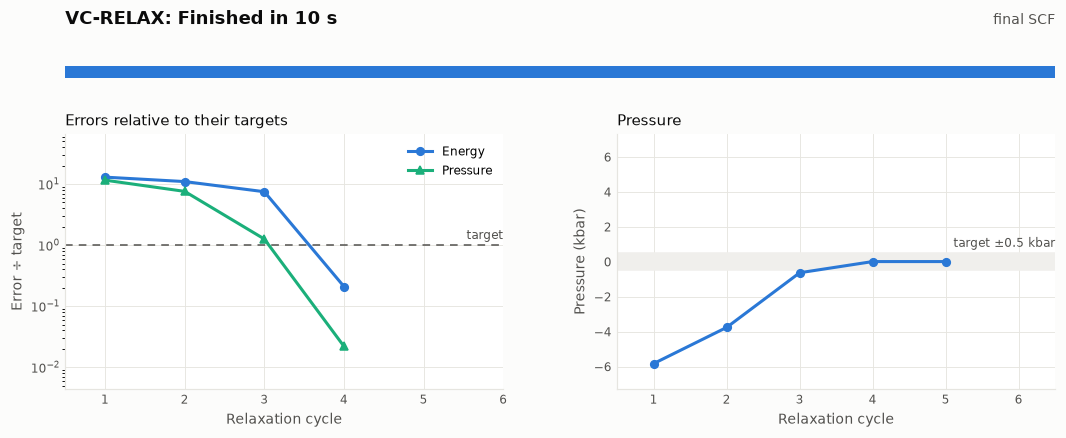

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 10.1 s
[PASS] Relaxation converged
Relaxed lattice parameter: 7.63075 bohr


In [37]:
AL_RELAX_OUT = run_pw("pw.scf.vc_al.in", AL_RELAX_INPUT, AL_RUN)

# Lattice parameter for every later aluminum step
AL_ALAT = relaxed_alat(AL_RELAX_OUT)
print(f"Relaxed lattice parameter: {AL_ALAT:.5f} bohr")

### 3.2 SCF Calculation

In [38]:
AL_SCF_INPUT = f'''&CONTROL
  calculation= 'scf',
  restart_mode= 'from_scratch',
  prefix= 'al',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/'
/

&SYSTEM
  ibrav= 2,
  celldm(1)= {AL_ALAT:.5f},
  nat= 1,
  ntyp= 1,
  ecutwfc= 50,
  ecutrho= 500,
  occupations= 'smearing',
  smearing= 'gaussian',
  degauss= 0.01
/

&ELECTRONS
  conv_thr= 1e-8
/

ATOMIC_SPECIES
  Al 26.981539 {AL_PSEUDO}

ATOMIC_POSITIONS (alat)
  Al 0.00 0.00 0.00

K_POINTS (automatic)
  10 10 10 0 0 0
'''

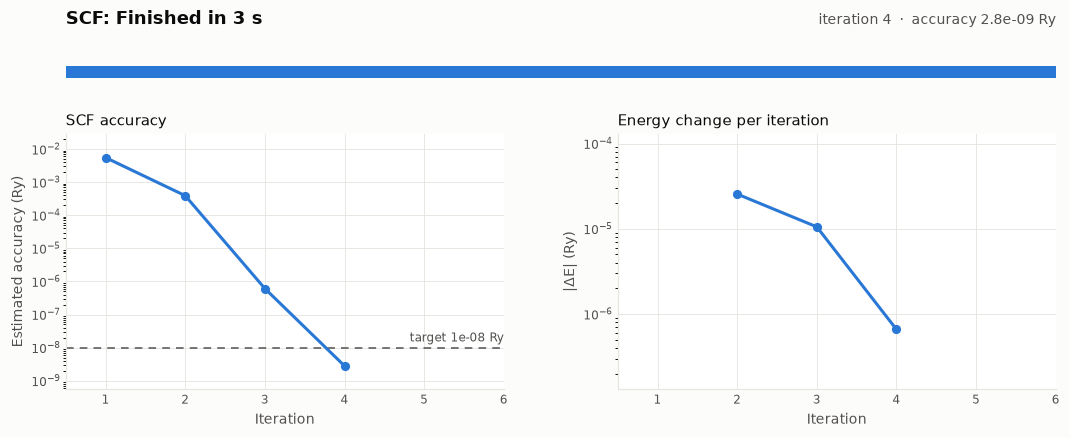

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 2.9 s
[PASS] SCF converged


In [39]:
AL_SCF_OUT = run_pw("pw.scf.al.in", AL_SCF_INPUT, AL_RUN)

### 3.3 NSCF Calculation

In [40]:
AL_NSCF_INPUT = f'''&CONTROL
  calculation= 'nscf',
  restart_mode= 'from_scratch',
  prefix= 'al',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  verbosity= 'high'
/

&SYSTEM
  ibrav= 2,
  celldm(1)= {AL_ALAT:.5f},
  nat= 1,
  ntyp= 1,
  ecutwfc= 50,
  ecutrho= 500,
  occupations= 'smearing',
  smearing= 'gaussian',
  degauss= 0.01
/

&ELECTRONS
  conv_thr= 1e-8
/

ATOMIC_SPECIES
  Al 26.981539 {AL_PSEUDO}

ATOMIC_POSITIONS (alat)
  Al 0.00 0.00 0.00

K_POINTS (automatic)
  40 40 40 0 0 0
'''

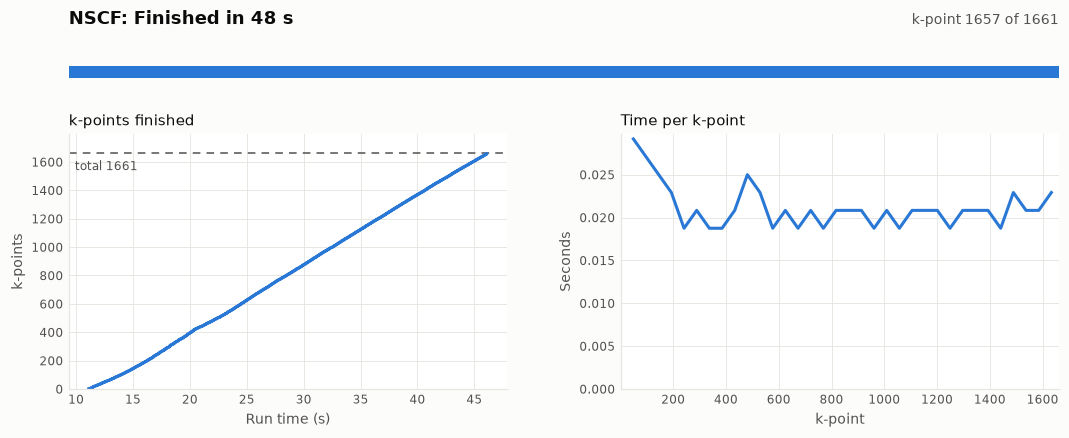

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 48.1 s
[PASS] NSCF finished


In [41]:
AL_NSCF_OUT = run_pw("pw.nscf.al.in", AL_NSCF_INPUT, AL_RUN)

### 3.4 Band Structure Calculation and Plotting

In [42]:
AL_BAND_INPUT = f'''&CONTROL
  calculation= 'bands',
  restart_mode= 'from_scratch',
  prefix= 'al',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  verbosity= 'high'
/

&SYSTEM
  ibrav= 2,
  celldm(1)= {AL_ALAT:.5f},
  nat= 1,
  ntyp= 1,
  ecutwfc= 50,
  ecutrho= 500,
  occupations= 'smearing',
  smearing= 'gaussian',
  degauss= 0.01
/

&ELECTRONS
  conv_thr= 1e-8
/

ATOMIC_SPECIES
  Al 26.981539 {AL_PSEUDO}

ATOMIC_POSITIONS (alat)
  Al 0.00 0.00 0.00

K_POINTS {{crystal_b}}
5
  00.000 0.500 00.000 20  !L
  00.000 0.000 00.000 30  !G
  -0.500 0.000 -0.500 10  !X
  -0.375 0.250 -0.375 30  !U
  00.000 0.000 00.000 20  !G
'''

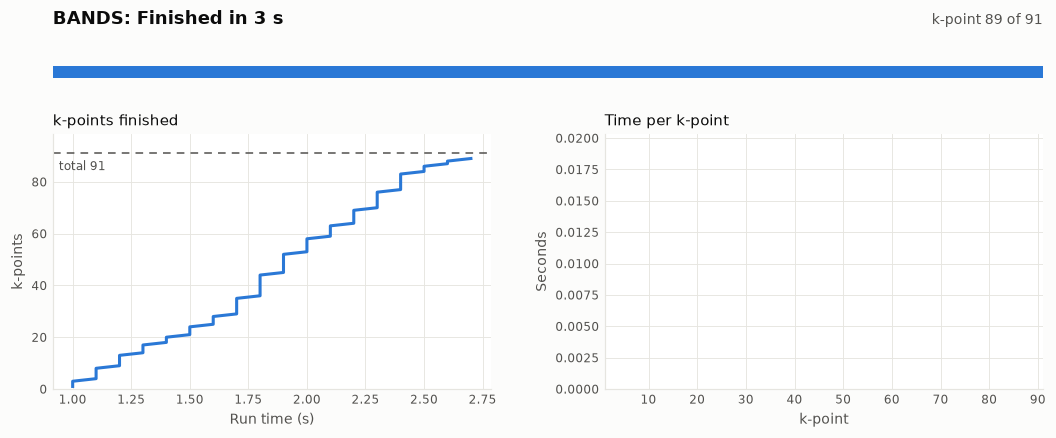

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 3.6 s
[PASS] Bands finished


In [43]:
AL_BAND_OUT = run_pw("pw.scf.bg_al.in", AL_BAND_INPUT, AL_RUN)

In [44]:
AL_POST = f'''&BANDS
  prefix = 'al'
  outdir = './tmp/'
  filband = 'al_bands.dat'
/
'''
(AL_RUN / "pw.scf.pp_al.in").write_text(AL_POST)

# Equivalent of:  bands.x < pw.scf.pp_al.in > pw.scf.pp_al.out
run_qe(BANDS, AL_RUN / "pw.scf.pp_al.in")
check("bands.x wrote data", (AL_RUN / "al_bands.dat.gnu").exists())

[PASS] bands.x wrote data


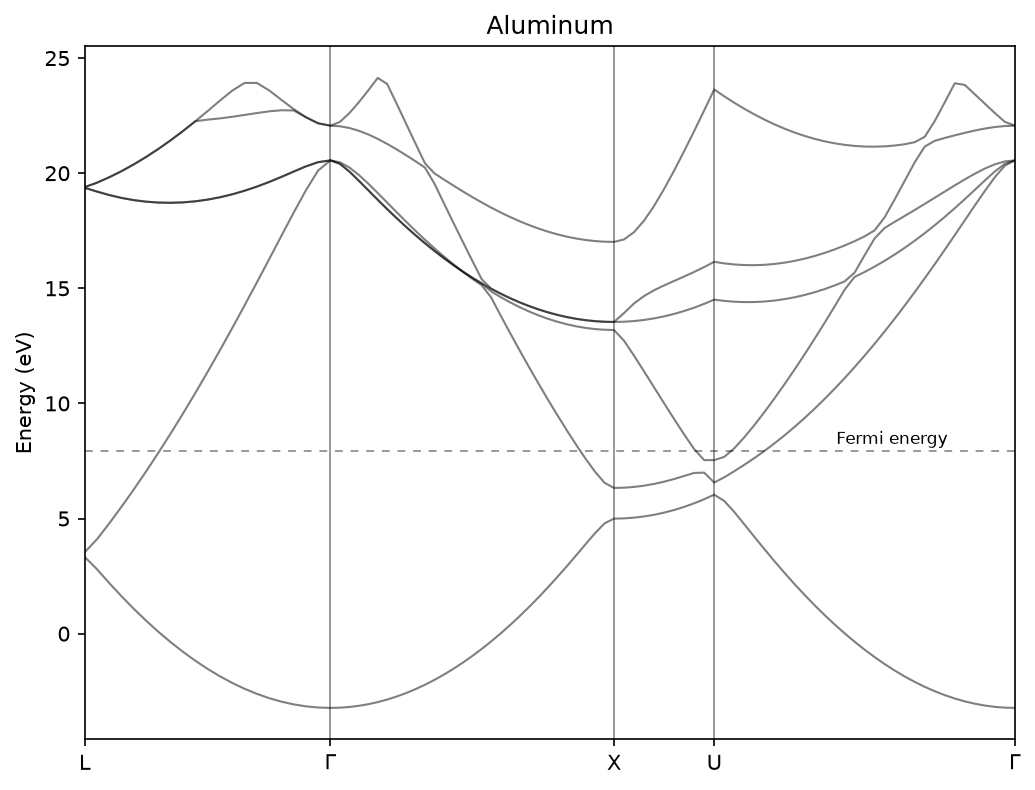

In [45]:
plot_bands(AL_RUN, "al_bands.dat", AL_RUN / "pw.scf.pp_al.out", AL_NSCF_OUT, "Aluminum", label_x=2.65)

## 4. Copper


The steps match aluminum, but copper's filled d band needs tighter settings. Each value below was chosen from convergence tests on this pseudopotential:

| Setting | Aluminum | Copper | Why copper differs |
|---|---|---|---|
| Starting `celldm(1)` | 7.652 bohr | 6.83 bohr | Experimental lattice parameter (3.615 Å) |
| `ecutwfc` / `ecutrho` | 50 / 500 Ry | 90 / 900 Ry | At 50 Ry the pressure is about 13 kbar off |
| `degauss` | 0.01 Ry | 0.02 Ry | Converges on a smaller k-grid |
| k-grid | 10×10×10 | 24×24×24 | A 10×10×10 grid shifts the Fermi energy by about 0.1 eV |

### 4.1 VC Relax Calculation

In [46]:
CU_RELAX_INPUT = f'''&CONTROL
  calculation= 'vc-relax',
  prefix= 'cu',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  etot_conv_thr= 1e-6,
  forc_conv_thr= 1e-5
/

&SYSTEM
  ibrav= 2,
  celldm(1)= 6.83,
  nat= 1,
  ntyp= 1,
  ecutwfc= 90,
  ecutrho= 900,
  occupations= 'smearing',
  smearing= 'gaussian',
  degauss= 0.02
/

&ELECTRONS
  conv_thr= 1e-8
/

&IONS
/

&CELL
  cell_dofree= 'ibrav'
/

ATOMIC_SPECIES
  Cu 63.546 {CU_PSEUDO}

ATOMIC_POSITIONS (alat)
  Cu 0.00 0.00 0.00

K_POINTS (automatic)
  24 24 24 0 0 0
'''

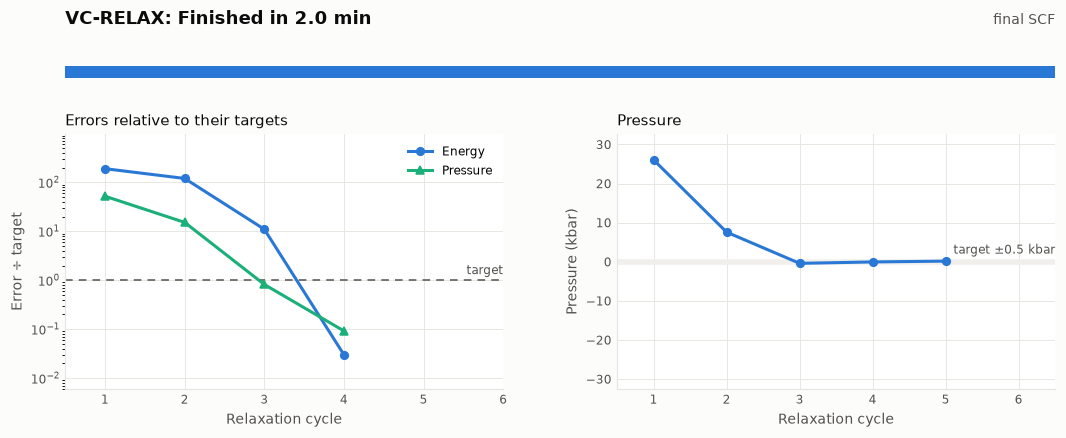

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 123.0 s
[PASS] Relaxation converged
Relaxed lattice parameter: 6.87210 bohr


In [47]:
CU_RELAX_OUT = run_pw("pw.scf.vc_cu.in", CU_RELAX_INPUT, CU_RUN)

# Lattice parameter for every later copper step
CU_ALAT = relaxed_alat(CU_RELAX_OUT)
print(f"Relaxed lattice parameter: {CU_ALAT:.5f} bohr")

### 4.2 SCF Calculation

In [48]:
CU_SCF_INPUT = f'''&CONTROL
  calculation= 'scf',
  restart_mode= 'from_scratch',
  prefix= 'cu',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/'
/

&SYSTEM
  ibrav= 2,
  celldm(1)= {CU_ALAT:.5f},
  nat= 1,
  ntyp= 1,
  ecutwfc= 90,
  ecutrho= 900,
  occupations= 'smearing',
  smearing= 'gaussian',
  degauss= 0.02
/

&ELECTRONS
  conv_thr= 1e-8
/

ATOMIC_SPECIES
  Cu 63.546 {CU_PSEUDO}

ATOMIC_POSITIONS (alat)
  Cu 0.00 0.00 0.00

K_POINTS (automatic)
  24 24 24 0 0 0
'''

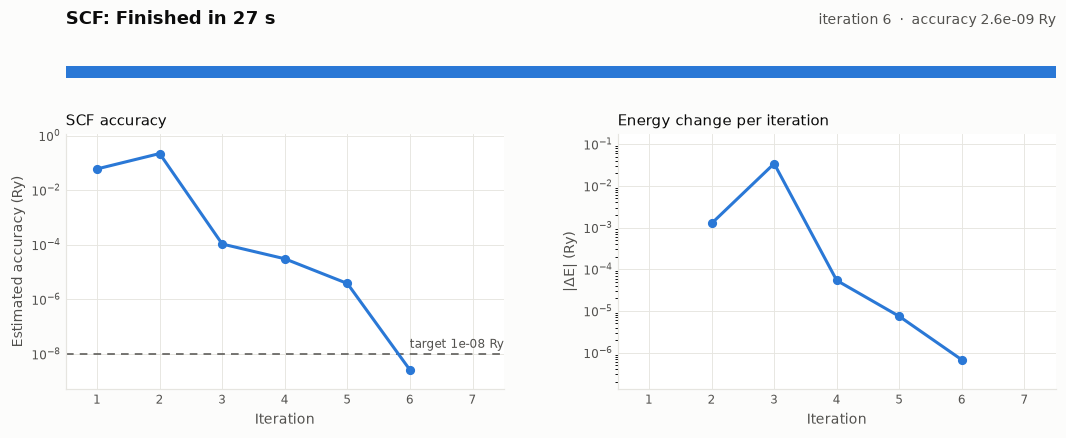

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 27.1 s
[PASS] SCF converged


In [49]:
CU_SCF_OUT = run_pw("pw.scf.cu.in", CU_SCF_INPUT, CU_RUN)

### 4.3 NSCF Calculation

In [50]:
CU_NSCF_INPUT = f'''&CONTROL
  calculation= 'nscf',
  restart_mode= 'from_scratch',
  prefix= 'cu',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  verbosity= 'high'
/

&SYSTEM
  ibrav= 2,
  celldm(1)= {CU_ALAT:.5f},
  nat= 1,
  ntyp= 1,
  ecutwfc= 90,
  ecutrho= 900,
  occupations= 'smearing',
  smearing= 'gaussian',
  degauss= 0.02
/

&ELECTRONS
  conv_thr= 1e-8
/

ATOMIC_SPECIES
  Cu 63.546 {CU_PSEUDO}

ATOMIC_POSITIONS (alat)
  Cu 0.00 0.00 0.00

K_POINTS (automatic)
  40 40 40 0 0 0
'''

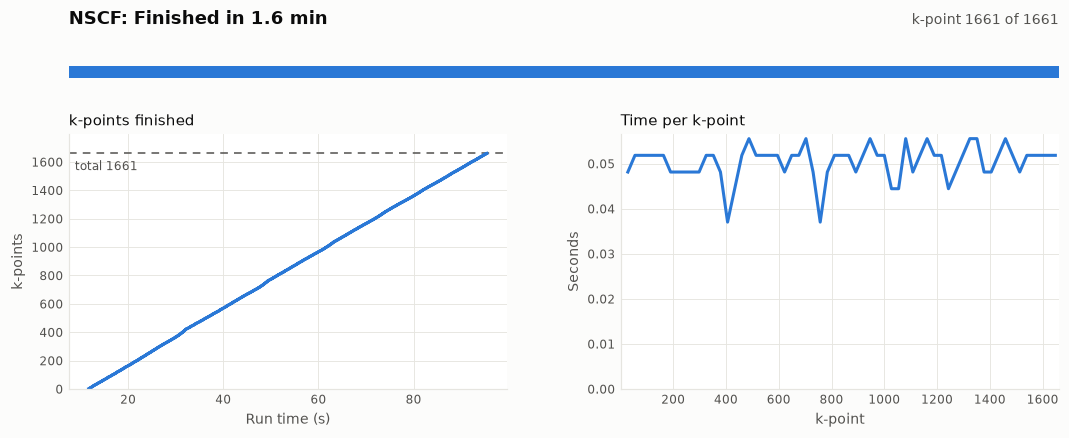

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 97.5 s
[PASS] NSCF finished


In [51]:
CU_NSCF_OUT = run_pw("pw.nscf.cu.in", CU_NSCF_INPUT, CU_RUN)

### 4.4 Band Structure Calculation and Plotting

In [52]:
CU_BAND_INPUT = f'''&CONTROL
  calculation= 'bands',
  restart_mode= 'from_scratch',
  prefix= 'cu',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  verbosity= 'high'
/

&SYSTEM
  ibrav= 2,
  celldm(1)= {CU_ALAT:.5f},
  nat= 1,
  ntyp= 1,
  ecutwfc= 90,
  ecutrho= 900,
  occupations= 'smearing',
  smearing= 'gaussian',
  degauss= 0.02
/

&ELECTRONS
  conv_thr= 1e-8
/

ATOMIC_SPECIES
  Cu 63.546 {CU_PSEUDO}

ATOMIC_POSITIONS (alat)
  Cu 0.00 0.00 0.00

K_POINTS {{crystal_b}}
5
  00.000 0.500 00.000 20  !L
  00.000 0.000 00.000 30  !G
  -0.500 0.000 -0.500 10  !X
  -0.375 0.250 -0.375 30  !U
  00.000 0.000 00.000 20  !G
'''

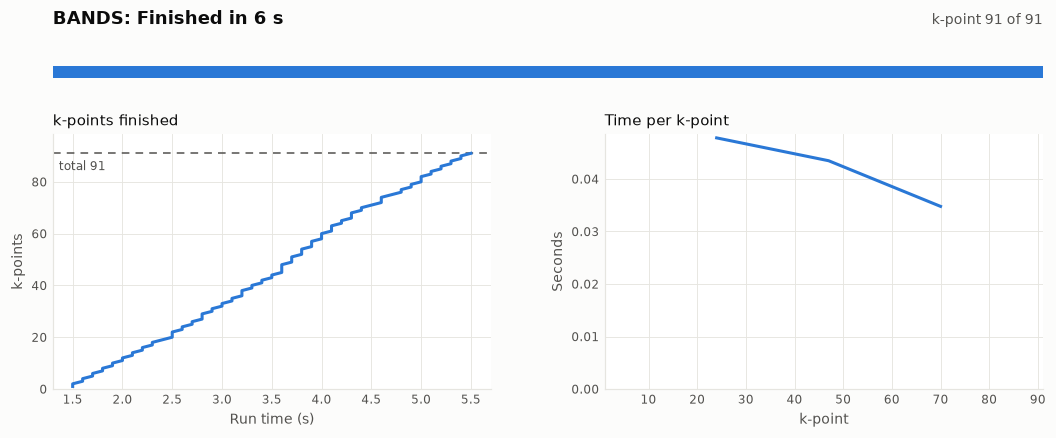

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 6.0 s
[PASS] Bands finished


In [53]:
CU_BAND_OUT = run_pw("pw.scf.bg_cu.in", CU_BAND_INPUT, CU_RUN)

In [54]:
CU_POST = f'''&BANDS
  prefix = 'cu'
  outdir = './tmp/'
  filband = 'cu_bands.dat'
/
'''
(CU_RUN / "pw.scf.pp_cu.in").write_text(CU_POST)

# Equivalent of:  bands.x < pw.scf.pp_cu.in > pw.scf.pp_cu.out
run_qe(BANDS, CU_RUN / "pw.scf.pp_cu.in")
check("bands.x wrote data", (CU_RUN / "cu_bands.dat.gnu").exists())

[PASS] bands.x wrote data


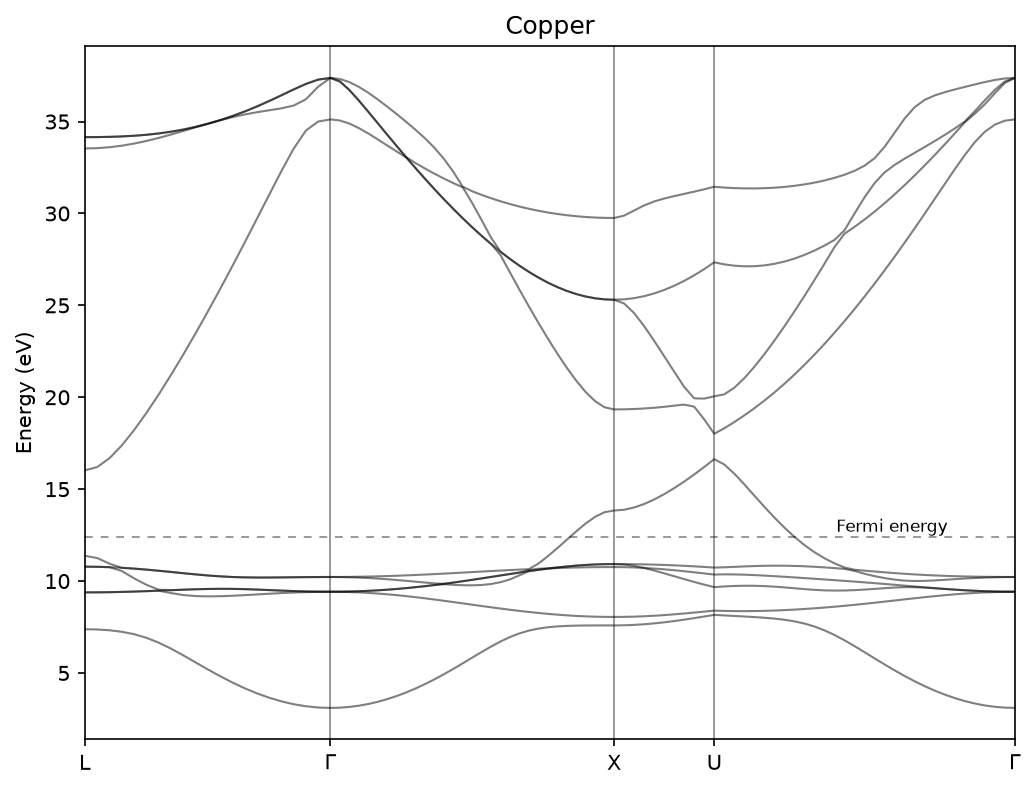

In [55]:
plot_bands(CU_RUN, "cu_bands.dat", CU_RUN / "pw.scf.pp_cu.out", CU_NSCF_OUT, "Copper", label_x=2.65)